## **Normalization**

### **MinMaxScaler**

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

In [84]:
wine = load_wine()
df = pd.DataFrame(wine.data,columns=wine.feature_names)
df['target'] = wine.target

In [85]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [86]:
df = df.iloc[:,[0,1,-1]]

In [87]:
df

,alcohol,malic_acid,target
0,14.23,1.71,0
1,13.20,1.78,0
2,13.16,2.36,0
3,14.37,1.95,0
4,13.24,2.59,0
...,...,...,...
173,13.71,5.65,2
174,13.40,3.91,2
175,13.27,4.28,2
176,13.17,2.59,2


<Axes: xlabel='alcohol', ylabel='Density'>

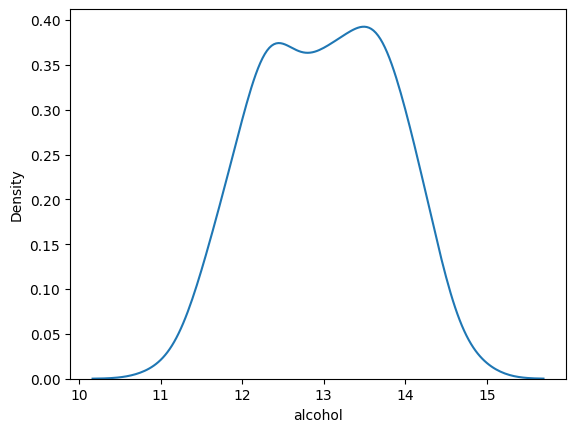

In [88]:
sns.kdeplot(df['alcohol'])

<Axes: xlabel='malic_acid', ylabel='Density'>

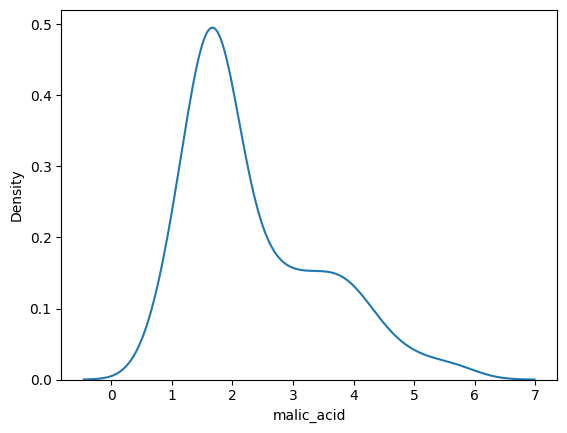

In [89]:
sns.kdeplot(df['malic_acid'])

<Axes: xlabel='alcohol', ylabel='malic_acid'>

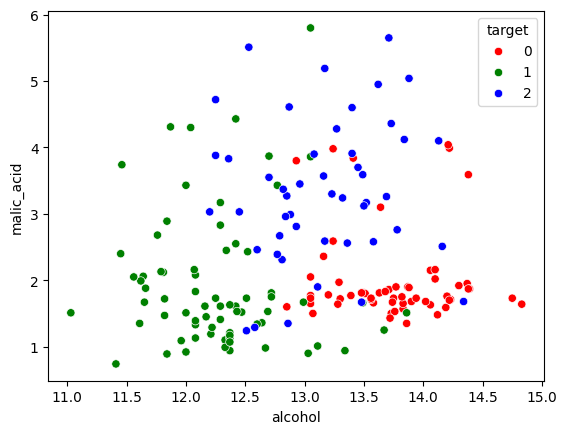

In [90]:
color_dict = {0 : 'red', 1: 'green', 2: 'blue'}
sns.scatterplot(x=df['alcohol'],y=df['malic_acid'],hue=df['target'],palette=color_dict)

In [91]:
from sklearn.model_selection import train_test_split

In [92]:
x_train , x_test, y_train , y_test = train_test_split(df.iloc[:,:-1],df['target'],
                                                      test_size=0.3,
                                                      random_state=42)

In [93]:
x_train.shape,x_test.shape

((124, 2), (54, 2))

In [94]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
# fit training set
scaler.fit(x_train)
# transform training and testing set
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [95]:
x_train_scaled = pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled,columns=x_test.columns)

In [96]:
np.round(x_train.describe(),1)

,alcohol,malic_acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.3,1.6
50%,12.9,1.9
75%,13.7,3.2
max,14.8,5.8


In [97]:
np.round(x_train_scaled.describe(),1)

,alcohol,malic_acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.3,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


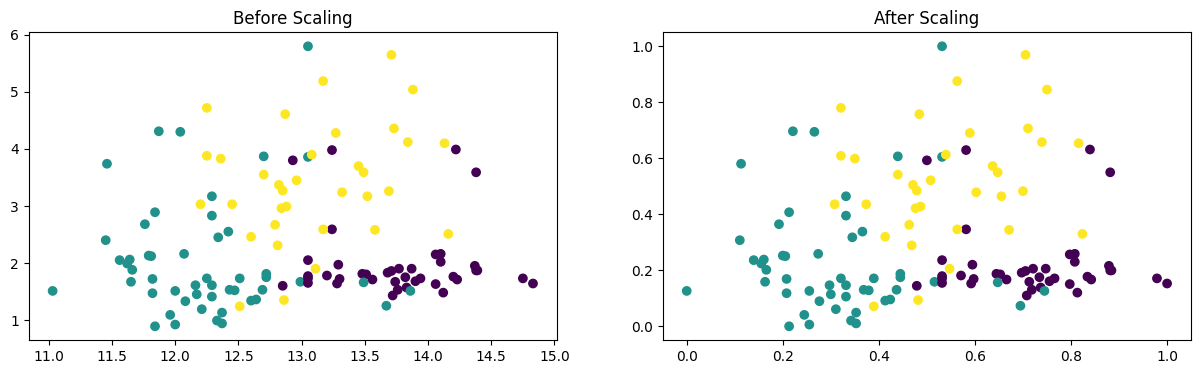

In [98]:
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize=(15,4))
ax1.set_title('Before Scaling')
ax1.scatter(x_train['alcohol'],x_train['malic_acid'],c= y_train)
ax2.scatter(x_train_scaled['alcohol'],x_train_scaled['malic_acid'],c= y_train)
ax2.set_title('After Scaling')
plt.show()

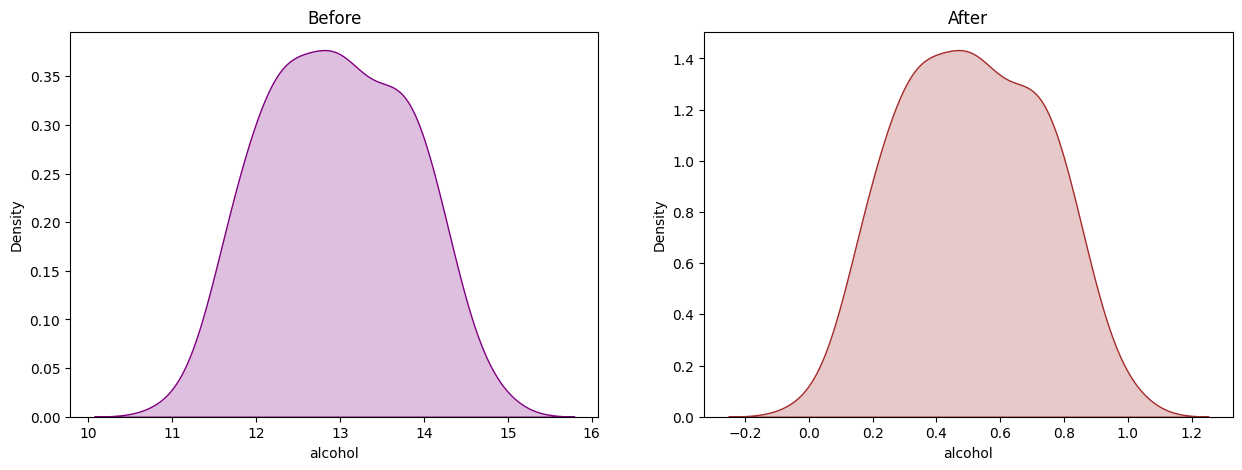

In [99]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize = (15,5))
ax1.set_title("Before")
ax2.set_title('After')
sns.kdeplot(x_train['alcohol'],ax= ax1,fill=True ,color='purple')
sns.kdeplot(x_train_scaled['alcohol'],ax=ax2,fill=True,color="brown")
plt.show()

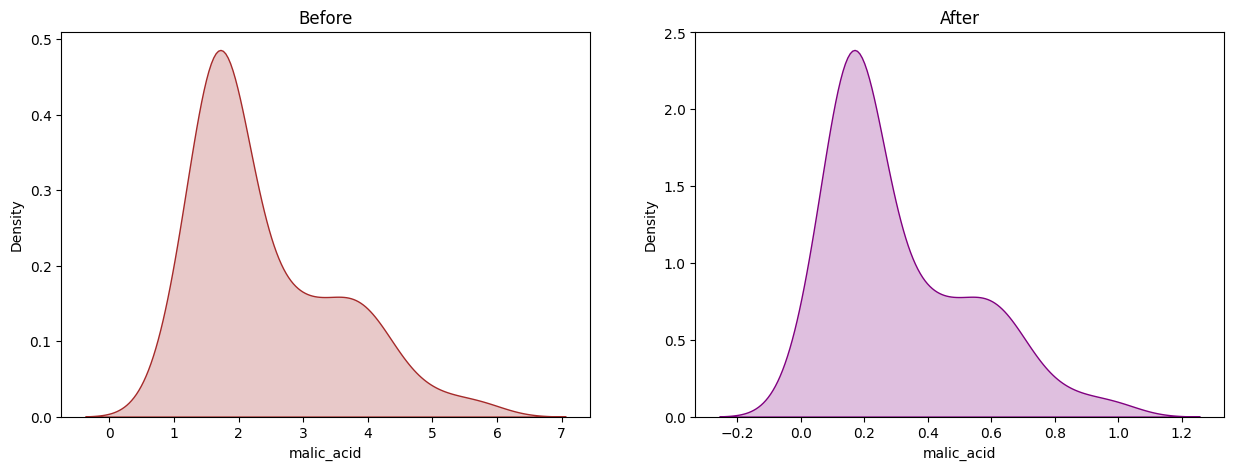

In [100]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize = (15,5))
ax1.set_title("Before")
ax2.set_title('After')
sns.kdeplot(x_train['malic_acid'],ax= ax1,fill=True,color='brown')
sns.kdeplot(x_train_scaled['malic_acid'],ax=ax2,fill=True,color='purple')
plt.show()

- distribution can be change in some cases.

## **RobustScaling**

In [101]:
titanic = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv")

In [102]:
titanic.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [103]:
titanic = titanic.iloc[:,[1,5,-3]]

In [104]:
titanic.isna().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [112]:
titanic['Age'] =  titanic['Age'].fillna(titanic['Age'].mean())

<Axes: title={'center': 'Age Distribution'}, xlabel='Age', ylabel='Density'>

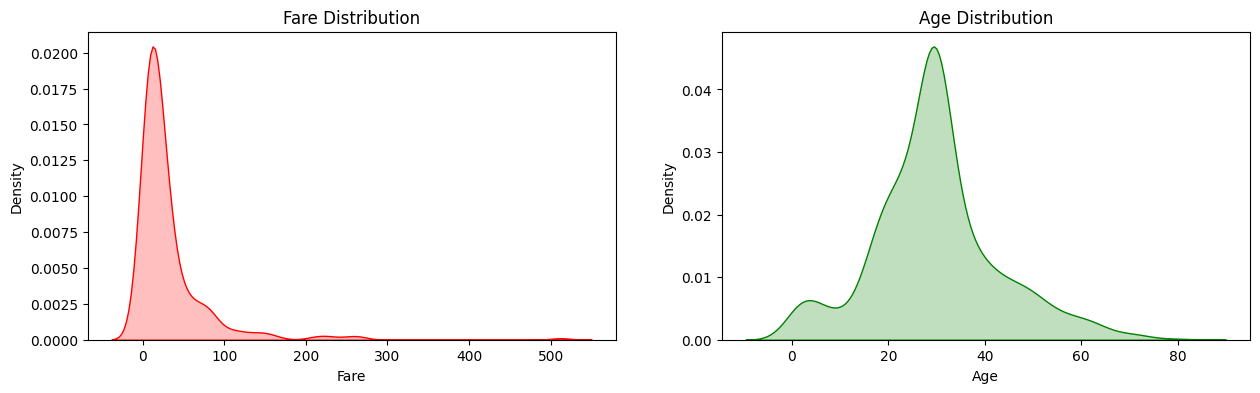

In [117]:
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize= (15,4))
ax1.set_title('Fare Distribution')
sns.kdeplot(titanic['Fare'],fill=True , color = 'red',ax=ax1)
ax2.set_title('Age Distribution')
sns.kdeplot(titanic['Age'],fill = True, color = 'green',ax=ax2)

In [106]:
x_train, x_test, y_train, y_test = train_test_split(titanic.iloc[:,1:],
                                                    titanic.iloc[:,0],test_size=0.3,random_state=42)

In [107]:
x_train.shape,x_test.shape

((623, 2), (268, 2))

In [119]:
from sklearn.preprocessing import RobustScaler

In [120]:
scaler = RobustScaler()
# fit training data
scaler.fit(x_train)
# transform train and test data
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [121]:
x_train_scaled = pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled,columns= x_test.columns)

In [123]:
np.round(x_train.describe(),1)

,Age,Fare
count,499.0,623.0
mean,29.3,31.8
std,14.6,51.0
min,0.4,0.0
25%,20.0,7.9
50%,28.0,14.5
75%,38.0,30.8
max,80.0,512.3


In [124]:
np.round(x_train_scaled.describe(),1)

,Age,Fare
count,499.0,623.0
mean,0.1,0.8
std,0.8,2.2
min,-1.5,-0.6
25%,-0.4,-0.3
50%,0.0,0.0
75%,0.6,0.7
max,2.9,21.8


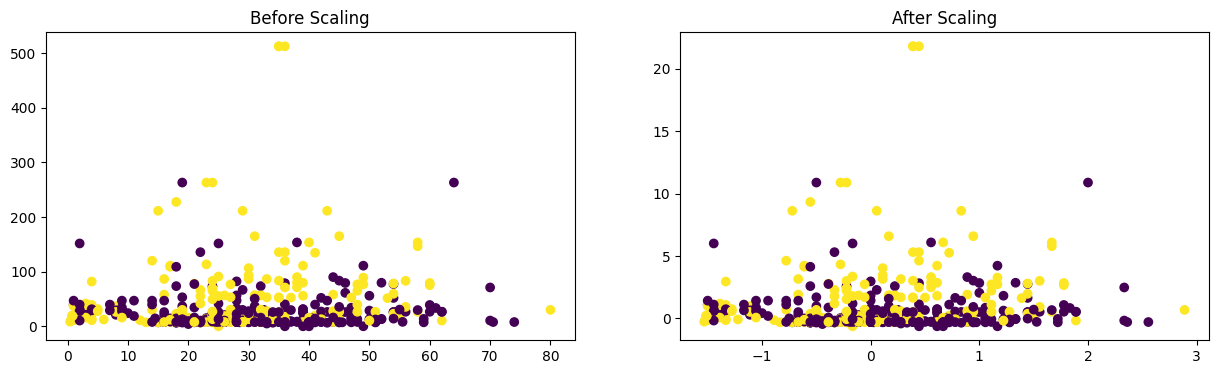

In [125]:
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize=(15,4))
ax1.set_title('Before Scaling')
ax1.scatter(x_train['Age'],x_train['Fare'],c= y_train)
ax2.scatter(x_train_scaled['Age'],x_train_scaled['Fare'],c= y_train)
ax2.set_title('After Scaling')
plt.show()

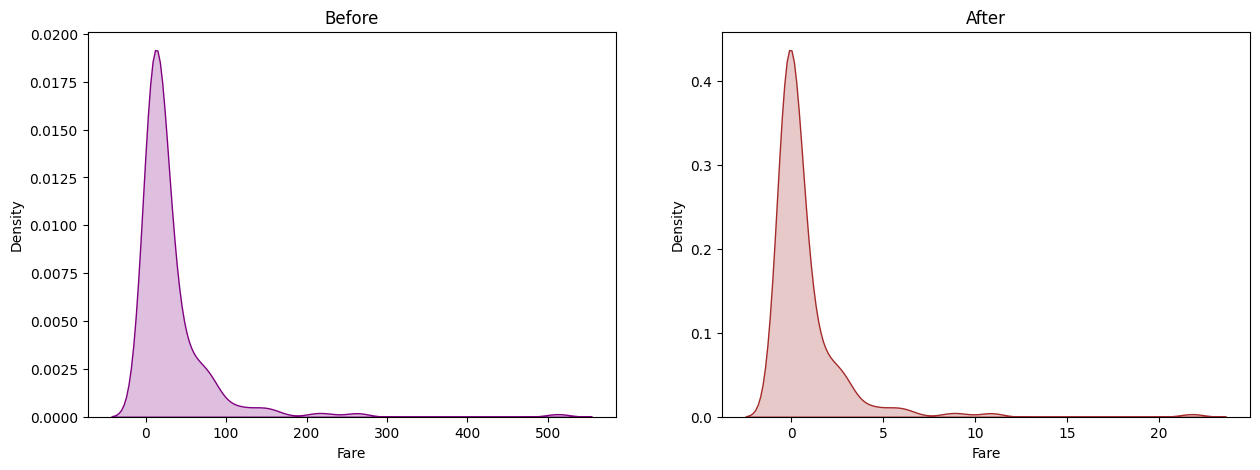

In [126]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize = (15,5))
ax1.set_title("Before")
ax2.set_title('After')
sns.kdeplot(x_train['Fare'],ax= ax1,fill=True ,color='purple')
sns.kdeplot(x_train_scaled['Fare'],ax=ax2,fill=True,color="brown")
plt.show()

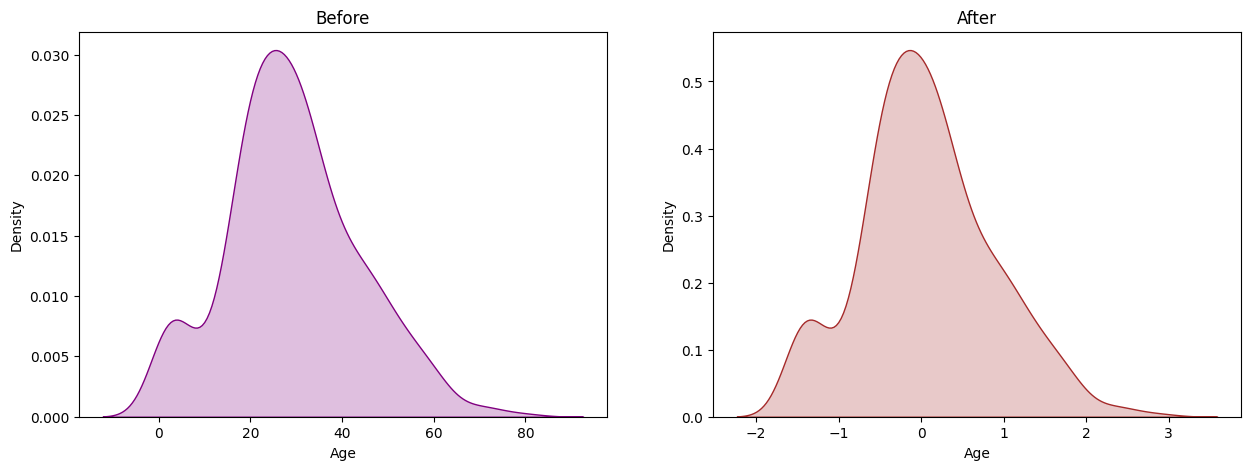

In [127]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize = (15,5))
ax1.set_title("Before")
ax2.set_title('After')
sns.kdeplot(x_train['Age'],ax= ax1,fill=True ,color='purple')
sns.kdeplot(x_train_scaled['Age'],ax=ax2,fill=True,color="brown")
plt.show()